In [22]:
!pip install mysql-connector-python pandas matplotlib seaborn

In [ ]:
import sys
sys.executable
import mysql.connector
import pandas as pd

def query(sql, params=None):
    conn = mysql.connector.connect(
        host="localhost",
        user="root",
        password=__import__("os").environ["MYSQL_PASSWORD"],
        database="classicmodels"
    )
    cursor = conn.cursor(dictionary=True)
    cursor.execute(sql, params or ())
    result = cursor.fetchall()
    cursor.close()
    conn.close()
    return result

# Test
query("SELECT COUNT(*) AS nb_clients FROM customers;")


[{'nb_clients': 122}]

### 4.1 — ANALYSE RFM (Recency, Frequency, Monetary)

In [ ]:
### Extraction des données

from datetime import datetime

sql = """
SELECT 
    c.customerNumber,
    c.customerName,
    o.orderNumber,
    o.orderDate,
    SUM(od.quantityOrdered * od.priceEach) AS order_amount
FROM customers c
JOIN orders o USING (customerNumber)
JOIN orderdetails od USING (orderNumber)
GROUP BY c.customerNumber, o.orderNumber;
"""

df = pd.DataFrame(query(sql))
df.head()

,customerNumber,customerName,orderNumber,orderDate,order_amount
0,363,Online Diecast Creations Co.,10100,2003-01-06,10223.83
1,128,"Blauer See Auto, Co.",10101,2003-01-09,10549.01
2,181,Vitachrome Inc.,10102,2003-01-10,5494.78
3,121,Baane Mini Imports,10103,2003-01-29,50218.95
4,141,Euro+ Shopping Channel,10104,2003-01-31,40206.20


In [31]:
### Calcul RFM
ref_date = df["orderDate"].max()

rfm = df.groupby(["customerNumber", "customerName"]).agg(
    Recency=("orderDate", lambda d: (ref_date - d.max()).days),
    Frequency=("orderNumber", "nunique"),
    Monetary=("order_amount", "sum")
).reset_index()

rfm.head()

,customerNumber,customerName,Recency,Frequency,Monetary
0,103,Atelier graphique,187,3,22314.36
1,112,Signal Gift Stores,183,3,80180.98
2,114,"Australian Collectors, Co.",183,5,180585.07
3,119,La Rochelle Gifts,0,4,158573.12
4,121,Baane Mini Imports,207,4,104224.79


In [32]:
### Scores + Segmentation
rfm["R_score"] = pd.qcut(rfm["Recency"], 4, labels=[4,3,2,1])
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1,2,3,4])
rfm["M_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1,2,3,4])

rfm["RFM_score"] = (
    rfm["R_score"].astype(int) +
    rfm["F_score"].astype(int) +
    rfm["M_score"].astype(int)
)

def segment(score):
    if score >= 10:
        return "VIP"
    elif score >= 7:
        return "Régulier"
    elif score >= 5:
        return "À risque"
    else:
        return "Perdu"

rfm["Segment"] = rfm["RFM_score"].apply(segment)

rfm.head()


,customerNumber,customerName,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment
0,103,Atelier graphique,187,3,22314.36,2,2,1,5,À risque
1,112,Signal Gift Stores,183,3,80180.98,3,2,2,7,Régulier
2,114,"Australian Collectors, Co.",183,5,180585.07,3,4,4,11,VIP
3,119,La Rochelle Gifts,0,4,158573.12,4,4,4,12,VIP
4,121,Baane Mini Imports,207,4,104224.79,2,4,3,9,Régulier


### 4.2 — MATRICE DE CORRÉLATION + HEATMAP

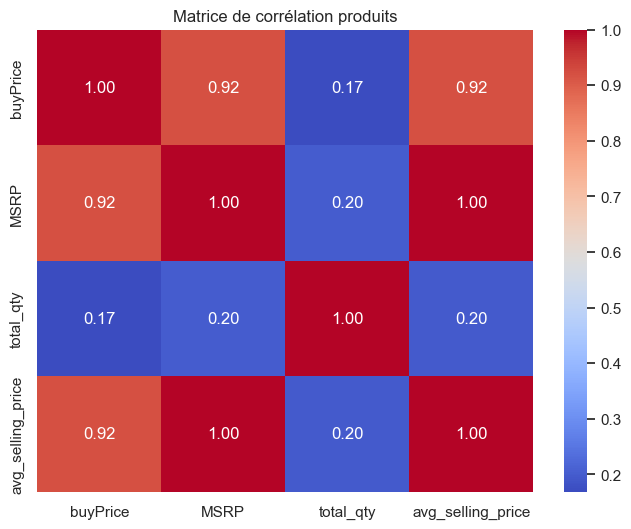

In [34]:
### Corrélations 
import seaborn as sns
import matplotlib.pyplot as plt

sql = """
SELECT 
    p.productCode,
    p.productName,
    p.buyPrice,
    p.MSRP,
    SUM(od.quantityOrdered) AS total_qty,
    AVG(od.priceEach) AS avg_selling_price
FROM products p
JOIN orderdetails od USING (productCode)
GROUP BY p.productCode;
"""

df_corr = pd.DataFrame(query(sql))

corr = df_corr[["buyPrice", "MSRP", "total_qty", "avg_selling_price"]].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation produits")
plt.show()


### 4.3 — SAISONNALITÉ (tendances temporelles)

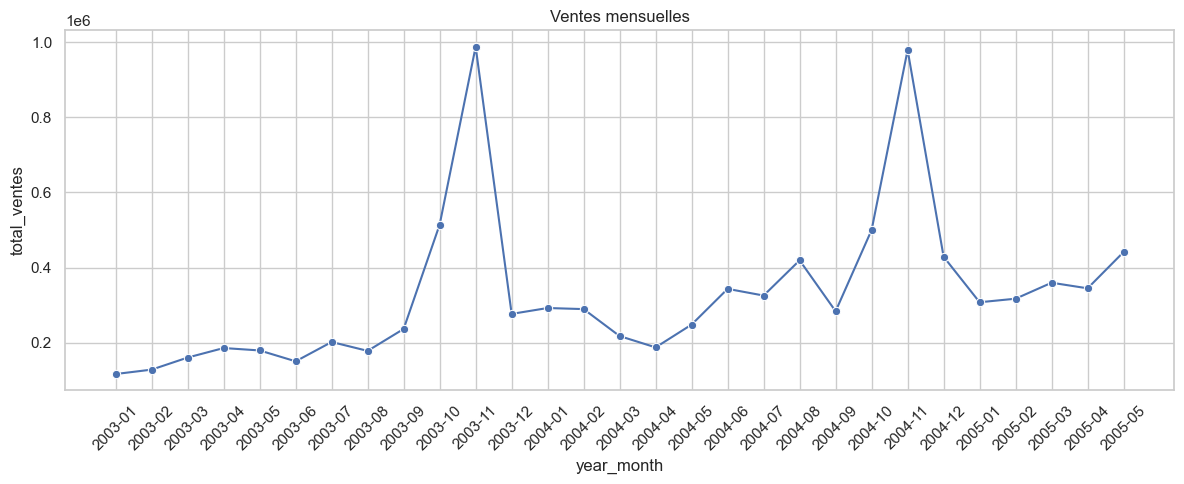

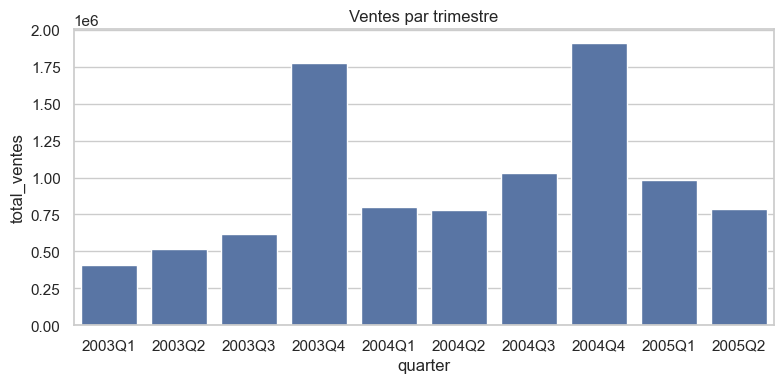

In [54]:
### Ventes mensuelles + trimestrielles
sql = """
SELECT 
    orderDate,
    SUM(quantityOrdered * priceEach) AS total_ventes
FROM orders
JOIN orderdetails USING (orderNumber)
GROUP BY orderDate
ORDER BY orderDate;
"""

df_time = pd.DataFrame(query(sql))
df_time["orderDate"] = pd.to_datetime(df_time["orderDate"])
df_time["year_month"] = df_time["orderDate"].dt.to_period("M").astype(str)
df_time["quarter"] = df_time["orderDate"].dt.to_period("Q").astype(str)

# Ventes mensuelles
monthly = df_time.groupby("year_month")["total_ventes"].sum().reset_index()

plt.figure(figsize=(12,5))
sns.lineplot(data=monthly, x="year_month", y="total_ventes", marker="o")
plt.xticks(rotation=45)
plt.title("Ventes mensuelles")

plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\partie4_visualisations\ventes_mensuelles.png")
plt.show()

# Ventes trimestrielles
quarterly = df_time.groupby("quarter")["total_ventes"].sum().reset_index()

plt.figure(figsize=(8,4))
sns.barplot(data=quarterly, x="quarter", y="total_ventes")
plt.title("Ventes par trimestre")


plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\partie4_visualisations\ventes_trimestrielles.png")
plt.show()

### 4.4 — PANIER MOYEN + PRODUITS ACHETÉS ENSEMBLE

In [41]:
### Panier moyen
sql = """
SELECT 
    o.orderNumber,
    SUM(od.quantityOrdered * od.priceEach) AS order_total
FROM orders o
JOIN orderdetails od USING (orderNumber)
GROUP BY o.orderNumber;
"""

df_panier = pd.DataFrame(query(sql))
df_panier["order_total"].mean()

np.float64(29460.707392638036)

In [42]:
### Produits achetés ensemble
from itertools import combinations
from collections import Counter

sql = """
SELECT 
    orderNumber,
    productCode
FROM orderdetails;
"""

df_pairs = pd.DataFrame(query(sql))

pairs = []

for order, group in df_pairs.groupby("orderNumber"):
    products = list(group["productCode"].unique())
    if len(products) > 1:
        pairs.extend(combinations(sorted(products), 2))

top_pairs = Counter(pairs).most_common(10)
top_pairs


[(('S50_1341', 'S700_1691'), 28),
 (('S18_2957', 'S18_3136'), 27),
 (('S18_2319', 'S18_3232'), 27),
 (('S24_2841', 'S24_3420'), 27),
 (('S24_3949', 'S700_4002'), 27),
 (('S700_2047', 'S72_1253'), 27),
 (('S18_2325', 'S24_1937'), 26),
 (('S700_3962', 'S72_3212'), 26),
 (('S10_2016', 'S18_2625'), 26),
 (('S12_1099', 'S12_3990'), 26)]

### 4.5 — PERFORMANCE DES EMPLOYÉS

In [44]:
### Extraction + calculs
sql = """
SELECT 
    e.employeeNumber,
    CONCAT(e.firstName, ' ', e.lastName) AS employeeName,
    COUNT(DISTINCT c.customerNumber) AS nb_clients,
    COUNT(DISTINCT o.orderNumber) AS nb_commandes,
    SUM(od.quantityOrdered * od.priceEach) AS chiffre_affaires
FROM employees e
JOIN customers c ON c.salesRepEmployeeNumber = e.employeeNumber
JOIN orders o ON o.customerNumber = c.customerNumber
JOIN orderdetails od ON od.orderNumber = o.orderNumber
GROUP BY e.employeeNumber;
"""

df_emp = pd.DataFrame(query(sql))
df_emp["panier_moyen"] = df_emp["chiffre_affaires"] / df_emp["nb_commandes"]

df_emp

,employeeNumber,employeeName,nb_clients,nb_commandes,chiffre_affaires,panier_moyen
0,1165,Leslie Jennings,6,34,1081530.54,31809.72176470588235294117647
1,1166,Leslie Thompson,6,14,347533.03,24823.78785714285714285714286
2,1188,Julie Firrelli,6,14,386663.20,27618.80
3,1216,Steve Patterson,6,18,505875.42,28104.19
4,1286,Foon Yue Tseng,6,17,488212.67,28718.39235294117647058823529
5,1323,George Vanauf,8,22,669377.05,30426.22954545454545454545455
6,1337,Loui Bondur,6,20,569485.75,28474.2875
7,1370,Gerard Hernandez,7,43,1258577.81,29269.25139534883720930232558
8,1401,Pamela Castillo,10,31,868220.55,28007.11451612903225806451613
9,1501,Larry Bott,8,22,732096.79,33277.12681818181818181818182


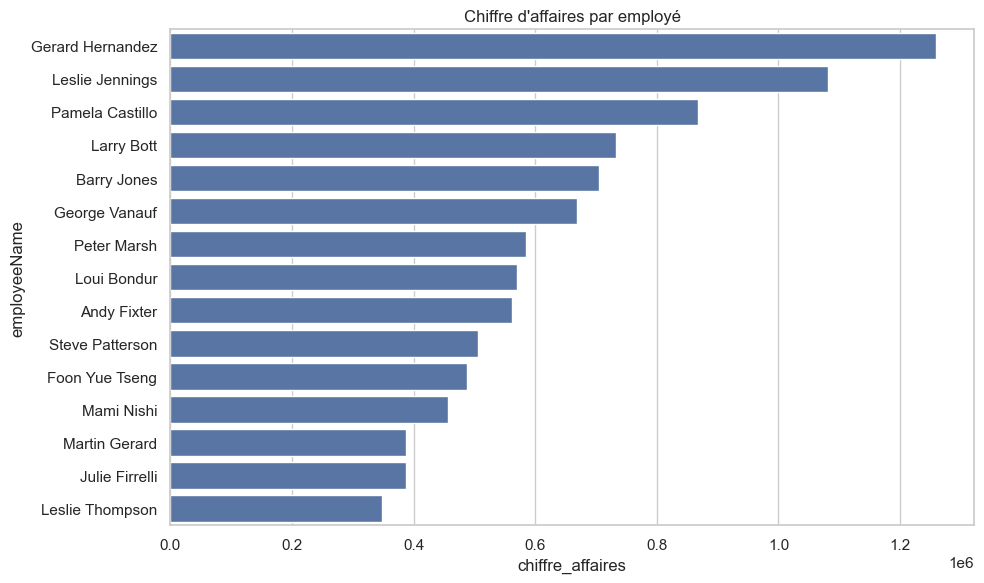

In [55]:
### Graphique performance employés
plt.figure(figsize=(10,6))
sns.barplot(data=df_emp.sort_values("chiffre_affaires", ascending=False),
            x="chiffre_affaires", 
            y="employeeName")
plt.title("Chiffre d'affaires par employé")

plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\partie4_visualisations\performance_employés.png")
plt.show()